In [2]:
import ipynb.fs.full.linear_regression as lr

scan 31 was

     dscan("m0", -4500, 4500, 19, Circles(), SaveImage(raw=True)).
     
m0 is aligned with the y-axis, so the movement should be in a straight vertical line around point 0.

In [3]:
scan = "0031_dscan"
data, cx, cy, hough_params =  lr.read_the_data(scan)

{'enabled': True, 'min_radius': 10, 'max_radius': 30, 'param1': 100, 'param2': 22, 'min_dist': 50, 'stabilise': True, 'hold_frames': 3}


,point,time,m0,m1,m2,x_rb,y_rb,s0,s1,s2,strain,frame_id,n_circles,cx,cy,radius,image
0,0,8.3973,-4500,0,0,-3.587832e-17,-0.585938,-4500,0,0,-0.366211,6939,1,290,50,17,images/0000.png
1,1,9.9502,-4000,0,0,-3.189184e-17,-0.520833,-4000,0,0,-0.325521,6983,1,292,110,18,images/0001.png
2,2,11.5651,-3500,0,0,-2.790536e-17,-0.455729,-3500,0,0,-0.284831,7025,1,294,112,17,images/0002.png
3,3,13.0952,-3000,0,0,-2.391888e-17,-0.390625,-3000,0,0,-0.244141,7069,1,292,122,18,images/0003.png
4,4,14.6922,-2500,0,0,-1.993240e-17,-0.325521,-2500,0,0,-0.203451,7113,1,292,140,18,images/0004.png
5,5,16.3174,-2000,0,0,-1.594592e-17,-0.260417,-2000,0,0,-0.162760,7157,1,294,162,17,images/0005.png
6,6,17.9313,-1500,0,0,-1.195944e-17,-0.195312,-1500,0,0,-0.122070,7200,1,294,186,18,images/0006.png
7,7,19.4962,-1000,0,0,-7.972961e-18,-0.130208,-1000,0,0,-0.081380,7244,1,294,204,18,images/0007.png
8,8,21.1100,-500,0,0,-3.986480e-18,-0.065104,-500,0,0,-0.040690,7287,1,292,224,18,images/0008.png
9,9,22.6859,0,0,0,0.000000e+00,0.000000,0,0,0,0.000000,7329,1,294,240,18,images/0009.png


np.polyfit slope and intercept :  28.90589569160994 -8276.15873015872
stats.linregress slope and intercept 28.90589569160998 -8276.158730158731


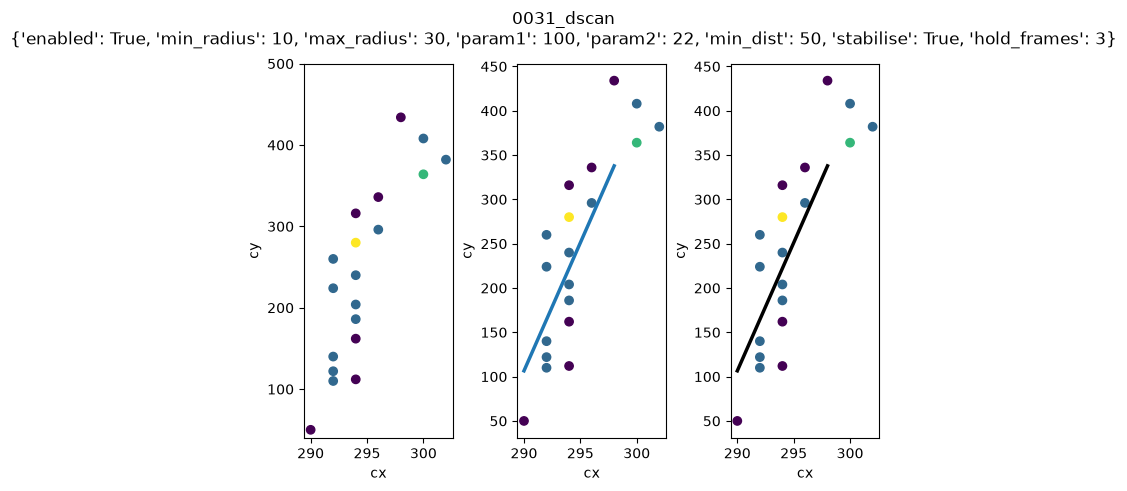

In [4]:
lr.subplot_linear(scan, hough_params, cx, cy, data["radius"], 40, 500, True)

y does increase, but there seems to be bunching around the bottom and there is variation in cx -> this could be due to the camera/bot/microscope not being completely aligned. However, the waviness at the end (where x starts to decrease again, would not be explained by this).

The gardient should, in theory, be infinite if it was a perfectly vertical line. --> easier to plot cy v cx to see how close the gradient is to 0. 

np.polyfit slope and intercept :  0.02383815301298568 288.93287916641714
stats.linregress slope and intercept 0.02383815301298546 288.93287916641737


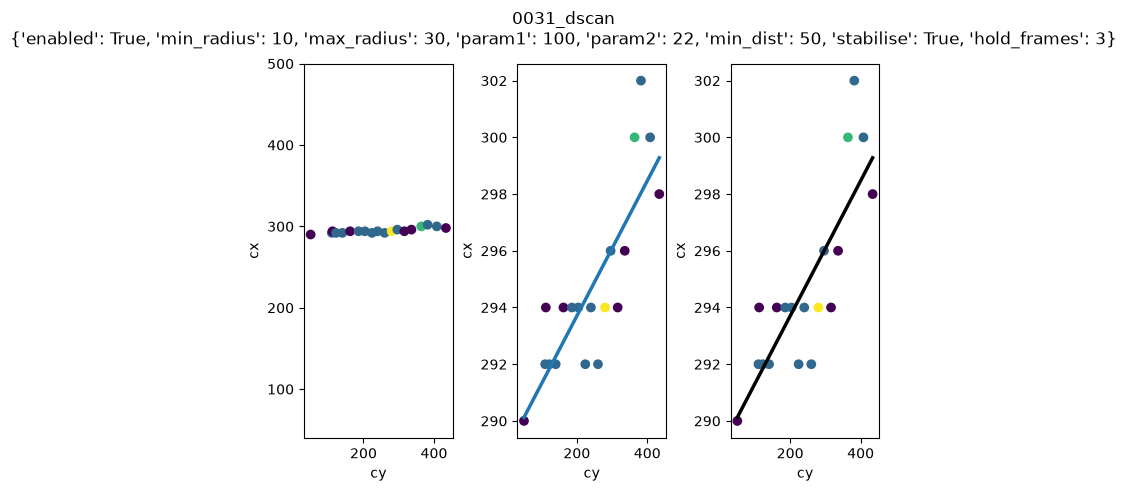

In [5]:
lr.subplot_linear(scan, hough_params, cy, cx, data["radius"], 40, 500, True)

The intercept is ~0.02 -> how to quantify if this is close enough to 0? 

we can also se again the jump from the first datapoint to a bunching of datapoints. They are not evenly spread out. 

Calculate difference between each datapoint in cy and plot:


0     NaN
1    60.0
2     2.0
3    10.0
4    18.0
Name: cy, dtype: float64


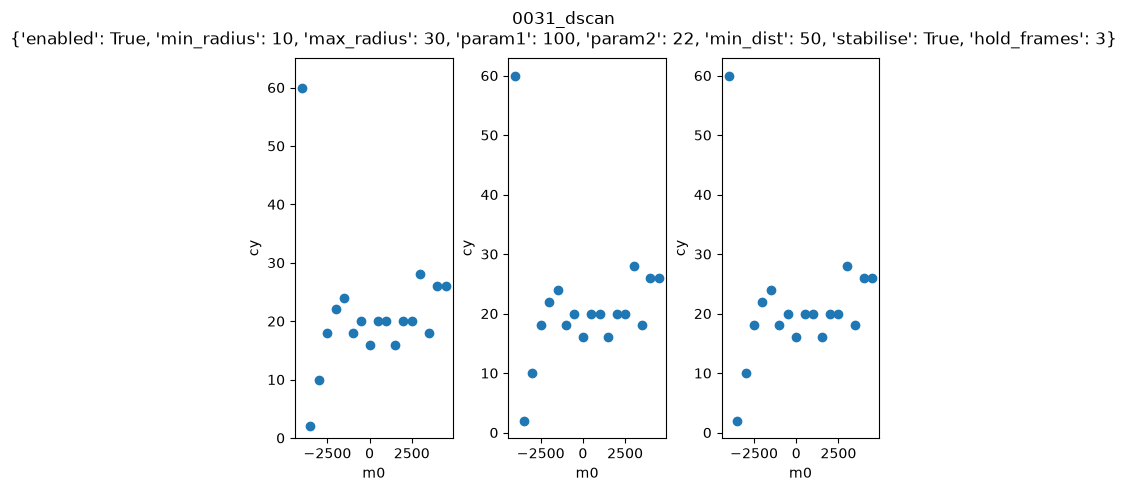

In [6]:
diff = cy.diff() #difference between each cy value and the previous value
print(diff.head(5))
lr.subplot_linear(scan, hough_params, data["m0"], diff, None, 0, 65, False)

Most of the gaps are around 20px, but the first gap is 60px, the second is only 2 and the third 10. This suggests something went wrong at the start - it was very jumpy. 
This could be from accidental movement of the table/bot, but I don't think so. - Might have to re-take the data to investigate further. 

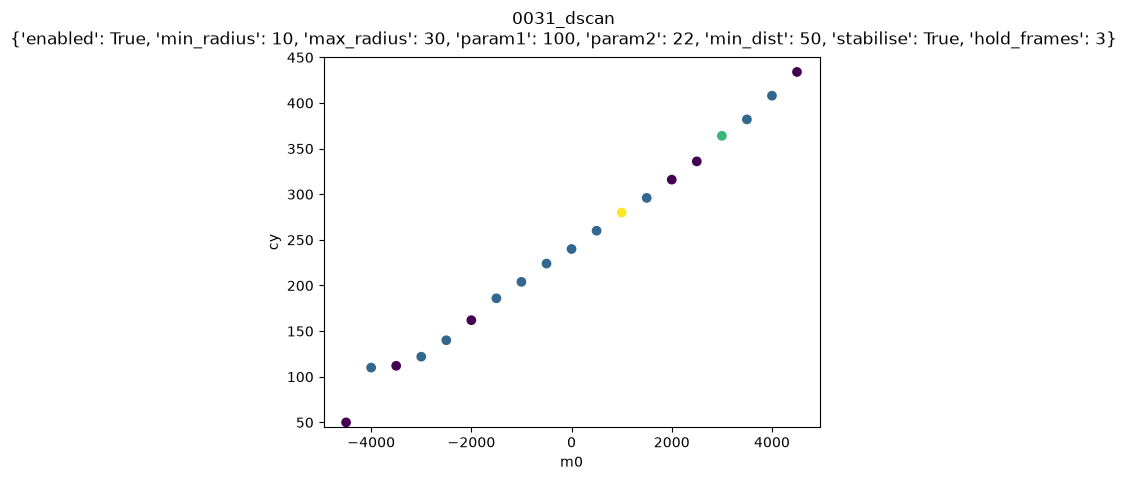

In [ ]:
lr.single_plot(scan, hough_params, data["m0"], cy, data["radius"], 45, 450, False)

The above plot also clearly shows the jump/buncing of the values near the start of the scan.

The m0 values are what is set in the scan instructions. They are evenly spaced. If the bot worked as expected, the cy values would also be evenly spaced. 

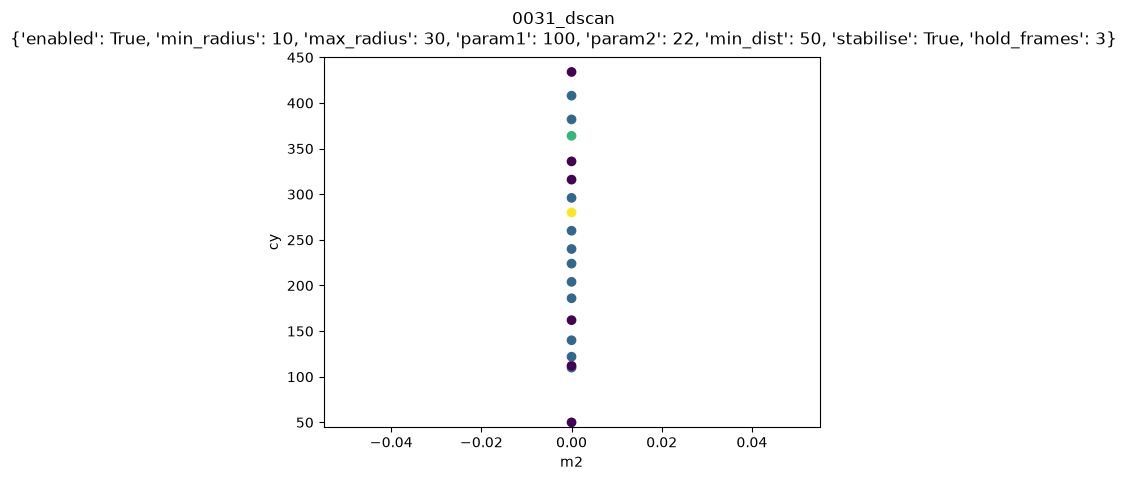

In [11]:
lr.single_plot(scan, hough_params, data["m2"], cy, data["radius"], 45, 450, False)

m1 and m2 are set to 0 for the whole scan, so this shows the bunching even more clearly. 

<h3>Variation in cx</h3>
Also want to investigate the weird variation in cx? 


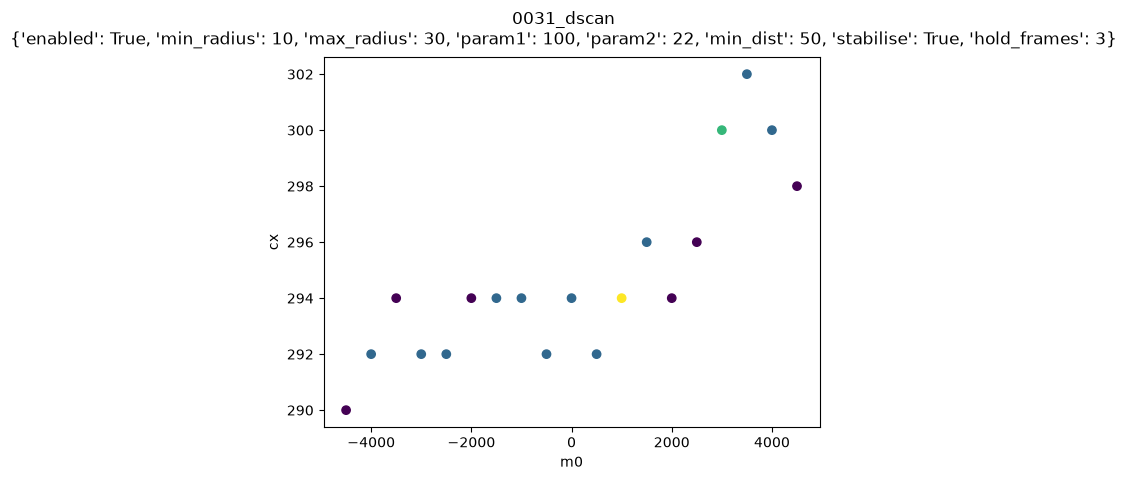

In [ ]:
lr.single_plot(scan, hough_params, data["m0"], cx, data["radius"], None, None, False)